# Clustering with Outlier Removal Implementation

In [31]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score, jaccard_score, f1_score

## Utility functions

COR Utilities

In [32]:
def generate_basic_partitions(X:pd.DataFrame, r:int, k_min:int = 2, k_max: int= None,seed:int = None)-> list[np.ndarray]:
    """
    Runs K-means on a data matrix to generate r basic partitions with variable number of clusters each. 
    Inputs:
    -   X: the data matrix;
    -   r: the number of basic partitions; 
    -   k_min: the minimum number of clusters in each partition. 2 by default;
    -   k_max: the maximum number of clusters that may compone each partition. No default value is provided;
    Outputs:
        The r partitions, in the form of a list of length r
    """
    if k_max is None:
        k_max = k_min**2
    elif k_max <k_min:
        print("Autofix - basic_partitioning: k_min greater than k_max; set to square.")
        k_max = k_min**2

    X = np.asarray(X,dtype = float)    
    basic_partitions = []
    np.random.seed(seed)
    for i in range(r):
        Kmeans_model = KMeans(n_clusters=np.random.randint(k_min,k_max+1), random_state=i, n_init=10)
        partition = Kmeans_model.fit_predict(X)
        basic_partitions.append(partition)
    return basic_partitions

def build_binary_matrices(partitions: list[np.ndarray])-> tuple[np.ndarray, np.ndarray]:
    """
    Constructs the binary matrices B and its complement, mapping observations from the original matrix and assigning 1 
    to the cell [l,ij] if, w.r.t. partition i, observation l belongs to cluster j.
    Input:
        The list of partitions.
    Output:
        Both matrix B and its complement.
    """
    cols = []
    for partition in partitions:
        for label in np.unique(partition):
            cols.append((partition ==label).astype(float))
    B = np.array(cols).T
    return B, 1-B

def generate_centroids(BB: list[np.ndarray], K: int)-> list[np.ndarray]:
    """
    Produces K centroids for the binary matrix BB, randomly variating the dimensions.
    Inputs:
    -   BB: the concatenated binary matrix
    -   K: the number of centroids (and clusters)
    Output:
        A list of K centroids randomly taken from BB with slightly varied values. 
    """
    uniques = np.unique(BB, axis = 0)
    if(K > BB.shape[0]):
        print("Numerical error: too much more clusters than observations. Cannot initialize centroids")
    elif (K > len(uniques)):
        print("Numerical error: not enough unique rows for K clusters. Cannot initialize centroids")

    return BB[np.random.choice(len(uniques), K, replace =False)].copy()

def compute_kl_distances(BB: np.ndarray, centroids: np.ndarray, return_matrix:bool= False) -> tuple[np.ndarray,np.ndarray]| tuple[np.ndarray,np.ndarray,np.ndarray]:
    """
    Computes the KL distances between all points of the matrix and the centroids. 
    Note that the we are working on the original formula is: D_KL(P(x)||Q(x)) = sum_P(x) log (P(x)/Q(x))
    and since b can be either 0 or 1, we have that:
    -   the limit for x->0 of xlog(x/m) is 0,
    -   1log(1/m) = - log(m),
    we directly compute the result as: - BB * log (m).
    Inputs:
    -   BB: the concatenated binary matrix 
    -   centroids: the vector of K centroids 
    -   return_matrix: whether the whole matrix should be returned or not
    Outputs: 
    -   the n x K matrix of distances, if 'return_matrix' is set to True
    -   the label of the cluster of the closest centroid
    -   the distance from the closest centroid
    """
    m = np.clip(centroids, 1e-12, None)
    distances = -(BB @ np.log2(m).T)
    if return_matrix:
        return distances, distances.argmin(axis=1), distances.min(axis = 1)
    return distances.argmin(axis=1), distances.min(axis = 1)

def extract_outliers(distances_vector: np.ndarray, how_many_o:int) ->np.ndarray:
    """
    Looks for the top 'how_many_o' values having the highest distance in the distance vector and provides
    their indexes.
    Inputs:
    -   the distance vector
    -   how_many_o: the number of outliers we are looking for
    Output:
        The vector of indexes of the outlier candidates.
    """
    if (how_many_o<= 0):
        return np.array([], dtype=int)
    return np.argsort(distances_vector)[-how_many_o:]

def update_centroids(BB:np.ndarray, labels: np.ndarray, old_centroids: np.ndarray) -> np.ndarray:
    """
    Updates the coordinates of the given centroids by arithmetic mean of the clusters components. The cluster belonging is defined 
    through a vector of labels.
    Inputs:
    -   BB: the concatenated binary matrix 
    -   labels: the vector of labels indicating the cluster of each data point
    -   old_centroids: the old vector of centroids
    Output:
        The new vector of centroids
    """
    centroids = old_centroids.copy()
    for k in range(len(old_centroids)):
        cluster = BB[labels == k]
        if(len(cluster) > 0):
            centroids[k] = cluster.mean(axis = 0)
    return centroids

def compute_holoentropy(BB: np.ndarray,labels: np.ndarray, centroids: np.ndarray) -> float:
    """
    Provides the result of the objective function on the K-means-- configuration dictated by the labels.
    The value is computed as the sum of the entropies for each cluster.
    Inputs:
    -   BB: the concatenated binary matrix
    -   labels: the vector of labels
    Output: 
        The objective value 
    """
    result = 0
    for k in range(len(centroids)):
        C_k = BB[labels == k] 
        if len(C_k) == 0:
            continue
        p = C_k.mean(axis= 0) 
        p = p[p > 0]   
        result += - len(C_k)* (p * np.log2(p)).sum() 
    return result

Datasets Utilities

In [33]:
def plot_correlation(df: pd.DataFrame):    
    """
    Creates a Heatmap using the correlation between an input dataframe's columns.
    Input:
        The dataframe 
    """     
    mask = np.triu(np.ones_like(df.corr(numeric_only=True), dtype=bool)) 

    plt.figure(figsize=(10, 8))
    sns.heatmap(df.corr(numeric_only=True), mask=mask, annot=True,cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5)
    plt.xticks(rotation=45, ha="right")
    plt.title("Correlation")
    plt.tight_layout()
    plt.show()

def make_categoric_partitions(df:pd.DataFrame, ignore: list = None) -> tuple[pd.DataFrame, list[np.ndarray]]:
    """
    Separates the categorical columns of a dataframe and turns them into partitions.
    
    Inputs:
    -   df: the dataframe
    -   ignore: the list with the names of the columns we wish to ignore; these will be removed 
        and won't be turned into partitions
    
    Outputs:
    -   the dataframe with only the remaining numerical columns
    -   the list of additional partitions
    """

    ignore = ignore or []
    categ_cols =[col for col in df.select_dtypes(exclude="number").columns if col not in ignore]
    partitions = [pd.factorize(df[col])[0] for col in categ_cols] 
    return df.drop(columns=categ_cols+ignore), partitions
    
def normalise(df: pd.DataFrame)-> pd.DataFrame:  #unused
    """
    Normalises each column of a given dataframe.
    """
    for col in df.columns:
        if df[col].dtype.kind not in "iuf":
            print("Dataset is not fully numeric. Force quitted.")
            return

    min = df.min(axis = 0)
    max = df.max(axis = 0)
    range = (max - min).replace(0,1)
    return (df - min)/range

def standardise(df: pd.DataFrame)-> pd.DataFrame:
    """
    Standardises each column of a given dataframe.
    """
    for col in df.columns:
        if df[col].dtype.kind not in "iuf":
            print("Dataset is not fully numeric. Force quitted.")
            return

    mean = df.mean(axis=0)
    std = df.std(axis=0).replace(0, 1)
    return (df - mean) / std

def PCA_scatter_plot(df: pd.DataFrame, labels: np.ndarray):
    p = PCA(2).fit_transform(df)
    inliers_mask = labels>=0
    plt.figure(figsize=(10,10))
    plt.scatter(p[inliers_mask,0], p[inliers_mask,1], c = labels[inliers_mask], cmap = "tab10", s = 33, alpha = 0.6)
    plt.scatter(p[labels ==-1, 0], p[labels ==-1, 1], marker = "x", c = "black", s = 20, label = "outliers found by COR")
    # plt.scatter(p[true_outliers, 0], p[true_outliers, 1], facecolors="none", edgecolors="red",
    #               s=70, label="real outliers")
    plt.legend()
    plt.show()

Evaluation utilities

In [34]:
def evaluate_COR(COR_labels: np.ndarray, true_labels: np.ndarray, true_outliers: np.ndarray = None) -> dict:
    """
    Computes the four metrics used in the paper to evaluate COR: NMI and R_n for clustering,
    Jaccard and F-measure for outlier detection.

    Inputs:
    -   COR_labels: the vector of labels assigned by COR
    -   true_labels: the vector of true classes
    -   true_outliers: a boolean vector of the true outliers (if not provided, only NMI and R_n are computed using observations with positive labels)
    
    Output:
        A dictionary with the values of all four metrics
    """
    
    if true_outliers is None:
        inliers_mask = COR_labels != -1
        return {"NMI": normalized_mutual_info_score(true_labels[inliers_mask], COR_labels[inliers_mask], average_method="geometric"),
                "R_n": adjusted_rand_score(true_labels[inliers_mask], COR_labels[inliers_mask]),
                "Jaccard": None, "F-measure": None}
    
    true_partition = np.where(true_outliers, -1, true_labels) 
    outliers_mask = COR_labels == -1
    return {"NMI": normalized_mutual_info_score(true_partition, COR_labels, average_method="geometric"),
            "R_n": adjusted_rand_score(true_partition, COR_labels),
            "Jaccard": jaccard_score(true_outliers, outliers_mask, zero_division=1.0),
            "F-measure": f1_score(true_outliers, outliers_mask, zero_division=0.0)}

def contingency_matrix(COR_labels: np.ndarray, true_labels: np.ndarray) -> np.ndarray:
    """
    Builds the contingency matrix between the partition obtained through COR and the true one.
    Each cell [i, j] contains the number of points in cluster i that belong to class j.
    
    Inputs:
    -   COR_labels: the vector of labels assigned by COR (rows)
    -   true_labels: the vector of true classes (cols)
    
    Output:
        The contingency matrix (n_clusters x n_classes)
    """
    return pd.crosstab(np.asarray(COR_labels), np.asarray(true_labels)).to_numpy()

## Algorithm

In [35]:
def COR(X: pd.DataFrame, K: int, o:int, r:int, n_init: int = 1, additional_bp: list = None, verbose: bool = False)-> tuple[np.ndarray, float, dict]:
    """
    Main function; runs the COR algorithm as presented in the paper. In this version, if the dataset contains categorical columns,
    it is left possible to use them as additional basic partitions. 
    
    Inputs:
    -   X: the data matrix
    -   K: the number of clusters
    -   o: the number of outliers
    -   r: the number of basic partitions generated by K-means
    -   n_init: the number of times we run K-means--
    -   additional_bp: the list of extra basic partitions 
    -   verbose: a boolean that, if set to True, enables a log of every iteration. False by default
    
    Outputs:
    -   The final partition in the form of a vector of labels
    -   The minimum objective value obtained
    -   Some run statistics
    """
    #setup
    basic_partitions_labels = generate_basic_partitions(X, r, k_max=2*K)
    if additional_bp:
        basic_partitions_labels += additional_bp #categorical columns are turned into basic partitions

    B, tilde_B = build_binary_matrices(basic_partitions_labels)
    BB = np.hstack([B,tilde_B])
    best_obj_value = np.inf
    best_labels = None
    run_statistics = {"iterations" : [], "labels" : [], "obj_values": []}


    for i in range(n_init): #we run K-means-- n_init times#
        centroids = generate_centroids(BB, K)
        iter = 0  
        prev_obj_value = np.inf  


        while (iter<1000):
            iter+= 1 
            c_labels, min_distances= compute_kl_distances(BB, centroids= centroids)
            outlier_candidates = extract_outliers(min_distances, o) 
            c_labels[outlier_candidates] = -1
            centroids = update_centroids(BB, c_labels,centroids)
            obj_value = compute_holoentropy(BB, c_labels, centroids)

            if(prev_obj_value < obj_value):
                print("Objective value increased: force-quitted.")

                break
            elif (prev_obj_value-obj_value<= 1e-10): #the while cycle terminates once the marginal difference gets too small
                break

            if verbose:
                print(f"Run: {i}. Iteration: {iter}; objective value: {obj_value}\n")
            prev_obj_value = obj_value


        if obj_value < best_obj_value:
            best_obj_value = obj_value
            best_labels = c_labels

        run_statistics["iterations"].append(iter)
        run_statistics["labels"].append(c_labels)
        run_statistics["obj_values"].append(obj_value)

    return best_labels, best_obj_value, run_statistics

## Datasets and tests

### Forestfires


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    object 
 3   day     517 non-null    object 
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), object(2)
memory usage: 52.6+ KB
None
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000  517.000000   
mean     4.669246    4.299807   90.644681  110.872340  547.940039    9.021663   
std      2.313778    1.229900

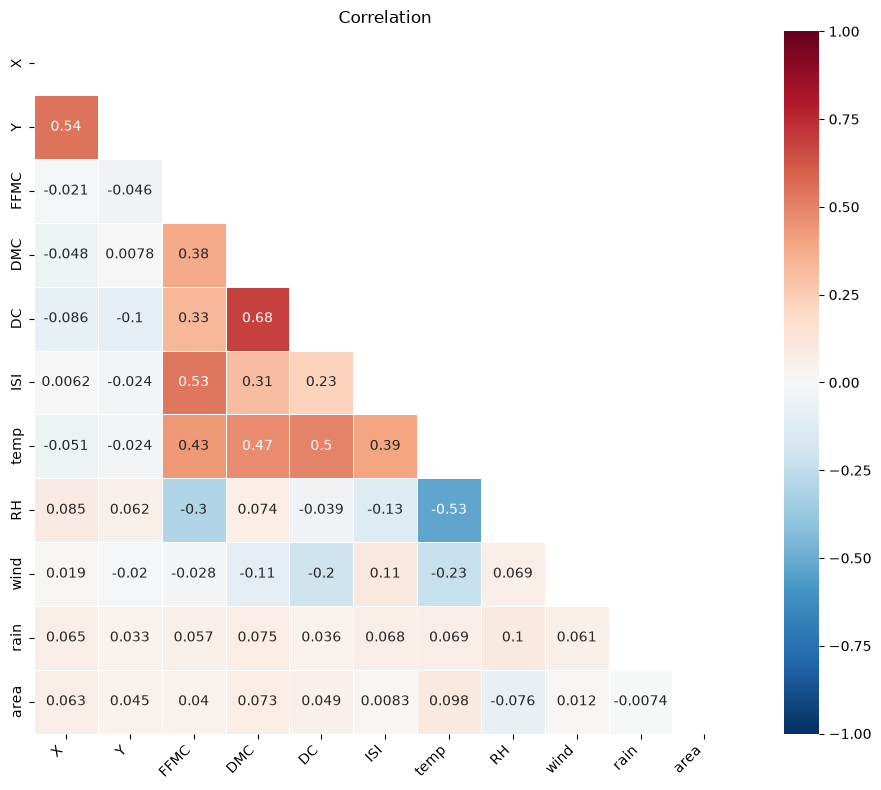

In [ ]:
fires = pd.read_csv("datasets/forestfires.csv")
# fires.info()
# fires.describe()
# plot_correlation(fires)

#---------------------------------------------------

fires, add_parts_fires = make_categoric_partitions(fires)
fires = standardise(fires)
cor_labels_fires,fires_obj, fires_stats = COR(fires, 3, int(len(fires)*0.05), 200,n_init=10, additional_bp=add_parts_fires)

PCA_scatter_plot(fires, cor_labels_fires)


### Wine

iteration: 0; objective value: 307411.374268927

iteration: 1; objective value: 285660.66528603935

iteration: 2; objective value: 260778.45026225626

iteration: 3; objective value: 240786.15779343108

iteration: 4; objective value: 239920.01264538208

iteration: 5; objective value: 239646.49154330592



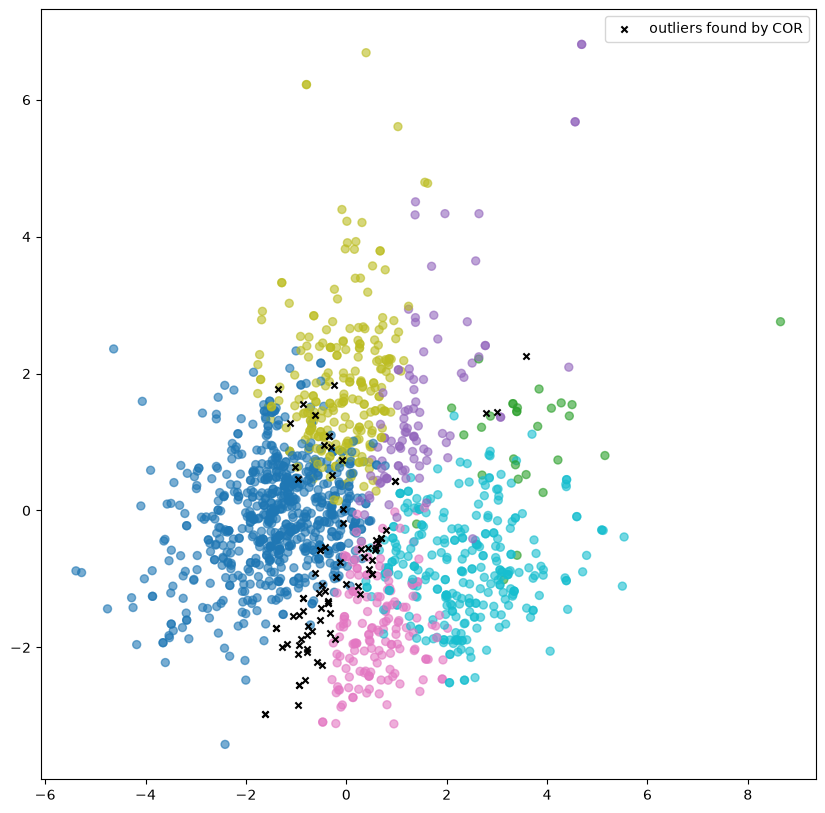

In [ ]:
red_wine_quality = pd.read_csv("datasets/wine+quality/winequality-red.csv",delimiter=";")
# red_wine_quality.info()
# red_wine_quality.describe()
target = red_wine_quality["quality"].to_numpy()
red_wine_quality.drop("quality",axis=1, inplace=True)
# plot_correlation(red_wine_quality)

# -----------------------------------------------------

red_wine_quality = standardise(red_wine_quality)
cor_labels_red_wine, _, _ = COR(red_wine_quality,len(np.unique(target)),int(len(red_wine_quality)*0.05), 100)

PCA_scatter_plot(red_wine_quality, cor_labels_red_wine)

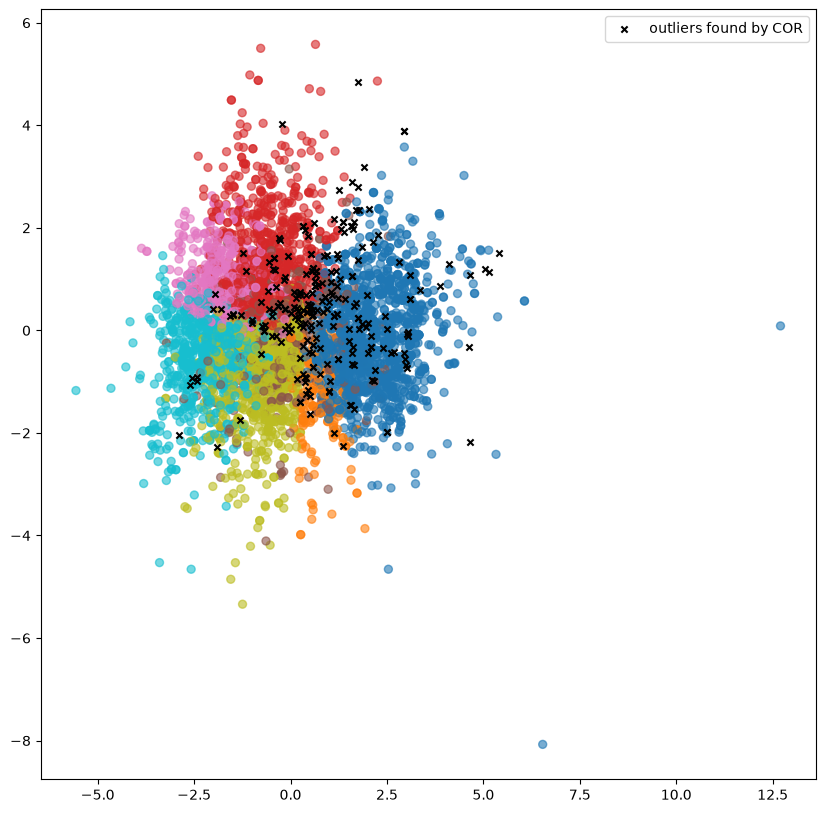

In [38]:
white_wine_quality = pd.read_csv("datasets/wine+quality/winequality-white.csv",delimiter=";")
# white_wine_quality.info()
# white_wine_quality.describe()
target = white_wine_quality["quality"].to_numpy()
white_wine_quality.drop("quality",axis = 1, inplace = True)
#plot_correlation(white_wine_quality)

# --------------------------------------------------------

white_wine_quality = standardise(white_wine_quality)

cor_labels_white_wine, _, _ = COR(white_wine_quality,len(np.unique(target)),int(len(white_wine_quality)*0.05), 200)
PCA_scatter_plot(white_wine_quality,labels=cor_labels_white_wine)

### Statlog Shuttle

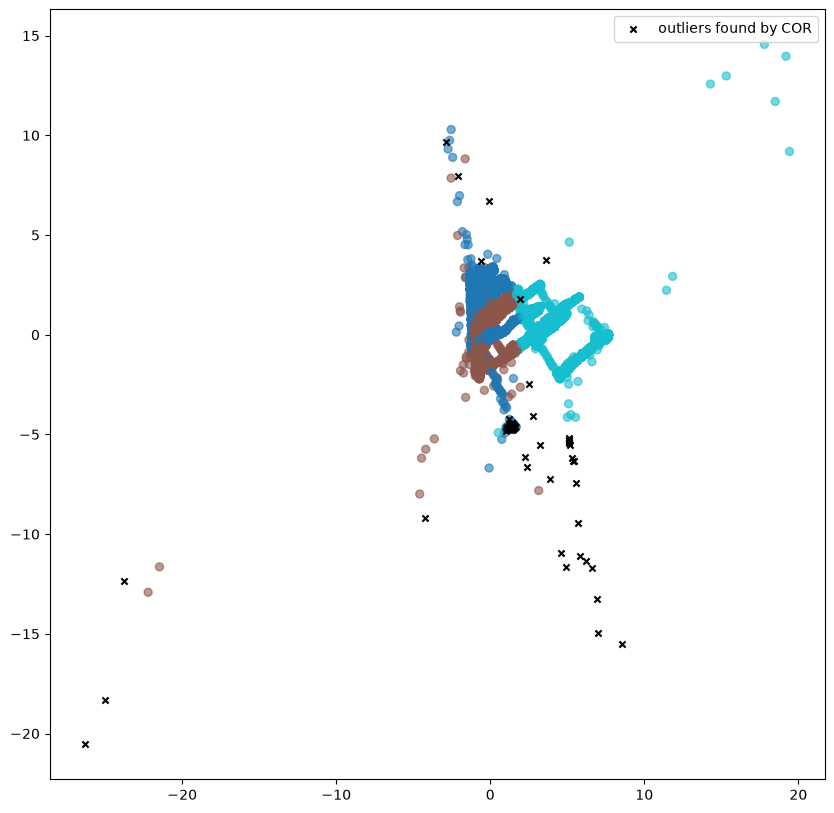

In [ ]:
header = ["A1", "A2", "A3", "A4", "A5", "A6", "A7", "A8", "A9", "Class"]
shuttle_train = pd.read_csv("datasets/statlog+shuttle/train_shuttle.csv", sep = ",",header=None, names=header)
shuttle_test  = pd.read_csv("datasets/statlog+shuttle/test_shuttle.csv", sep = ",",header=None, names = header)
shuttle = pd.concat([shuttle_train,shuttle_test], ignore_index=True)
# shuttle.info()
# shuttle.describe()
shuttle_target  = shuttle.Class
shuttle.drop("Class",axis = 1, inplace = True)
shuttle = standardise(shuttle)
# plot_correlation(shuttle)

# -------------------------------------------------

outlier_indexes = shuttle[shuttle_target.isin([2, 3, 6, 7])].index   # 2,3,6,7 are the classes considered outlier set by the paper; found with value_counts()
true_outliers_shuttle = np.zeros(len(shuttle), dtype=bool)
true_outliers_shuttle[outlier_indexes] = True


cor_labels_shuttle,shuttle_obj, stats = COR(shuttle, K = 3, o=len(true_outliers_shuttle[true_outliers_shuttle==True]),r = 300,n_init= 3)
PCA_scatter_plot(shuttle,cor_labels_shuttle)

## Performances Evaluation

In [29]:
evaluate_COR(cor_labels_shuttle,shuttle_target,true_outliers_shuttle)

{'NMI': 0.3249699432940875,
 'R_n': 0.4523806407857989,
 'Jaccard': 0.014553014553014554,
 'F-measure': 0.028688524590163935}